In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

import cartopy.crs as ccrs
import seaborn as sns

from importlib.resources import files
plt.style.use(files("nese.verify") / "nese.mplstyle")

In [31]:
ds = xr.open_zarr("runs/v2p1/inference-2015/forecast.zarr/")
#ds = xr.open_zarr("runs/v1/inference-2015/forecast.zarr/")

In [32]:
from nese.verify.maps import set_region, draw_cells, REGIONS

def projection(region: str) -> ccrs.Projection:
    """A projection that suits the region's aspect and latitude band."""
#    lon0, lon1, lat0, lat1 = REGIONS[region]
    lon0 = -99
    lon1 = 10
    lat0 = 0
    lat1 = 65
    lon_c, lat_c = (lon0 + lon1) / 2, (lat0 + lat1) / 2

    #return ccrs.LambertConformal(central_longitude=lon_c, central_latitude=lat_c)
    #return ccrs.Orthographic(central_longitude=lon_c, central_latitude=lat_c)
    #return ccrs.Orthographic(central_longitude=lon_c, central_latitude=lat_c)
    #return ccrs.Robinson(central_longitude=lon_c)
    return ccrs.Mollweide(central_longitude=lon_c)

In [33]:
plotme = ds["ugxt"].sel(fhr=24,t0="2015-05-26T12").load()

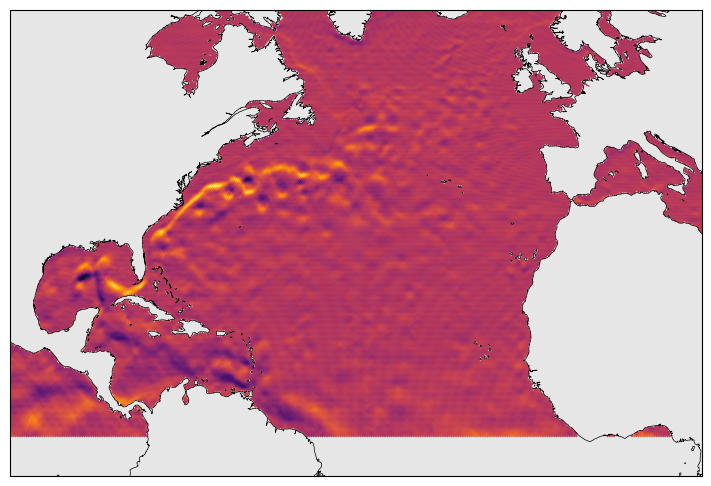

In [34]:
fig, ax = plt.subplots(subplot_kw={"projection": projection("north_atlantic")})
set_region(ax, "north_atlantic")
draw_cells(
    ax,
    plotme,
    attrs=ds.attrs,
)

In [2]:
ds = xr.open_dataset("runs/v2p1/inference-validation/metrics/sla.overlap.nc")

In [3]:
ds = ds.squeeze()

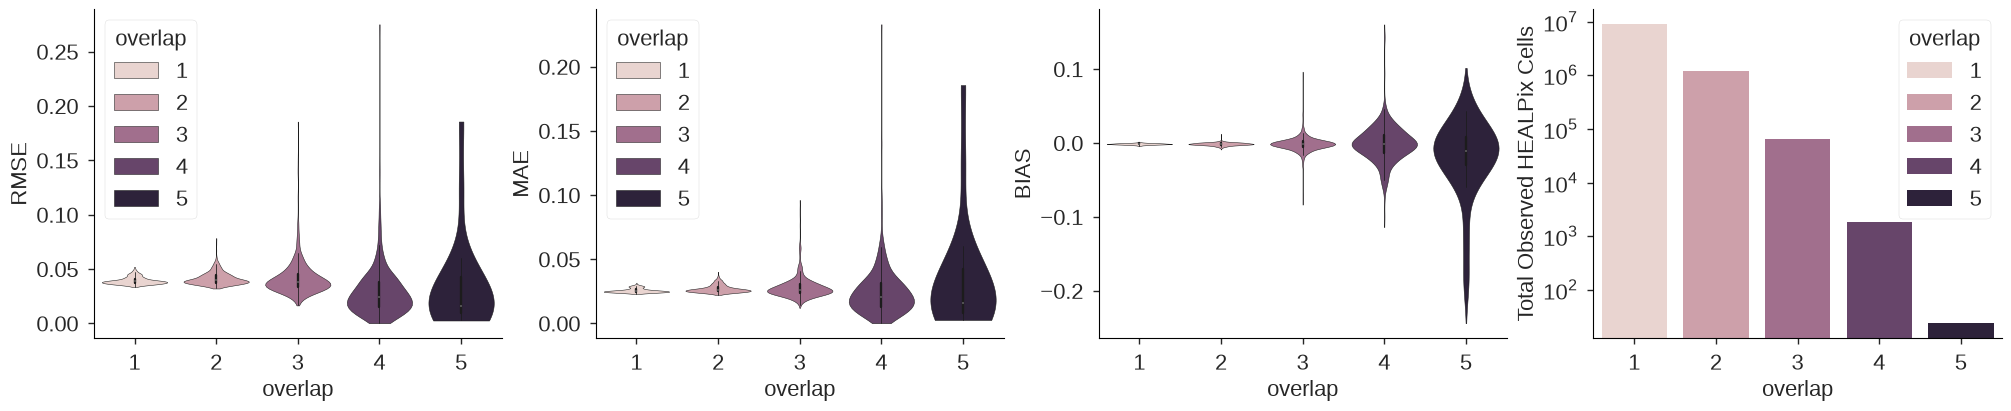

In [6]:
reference = "jason_3"
metrics = ["rmse", "mae", "bias"]
ncols = len(metrics)+1
fig, axs = plt.subplots(1, ncols, figsize=(5*ncols, 4))

for metric, ax in zip(metrics, axs):
    plotme = ds[metric].sel(group=reference).to_dataset().to_dataframe()
    kwargs = {"cut": 0} if metric != "bias" else {}
    sns.violinplot(
        data=plotme,
        x="overlap",
        y=metric,
        hue="overlap",
        ax=ax,
        legend=True if metric != "bias" else False,
        **kwargs,
    )
    ax.set(ylabel=metric.upper())

sns.barplot(
    data=ds["n_obs"].sel(group=reference).sum("t0").to_dataset().to_dataframe(),
    x="overlap",
    y="n_obs",
    hue="overlap",
    ax=axs[-1],
#    legend=False
)
axs[-1].set(yscale="log", ylabel="Total Observed HEALPix Cells")

fig.savefig(f"runs/v2p1/inference-validation/figures/metrics.overlap.{reference}.jpeg", dpi=300, bbox_inches="tight")

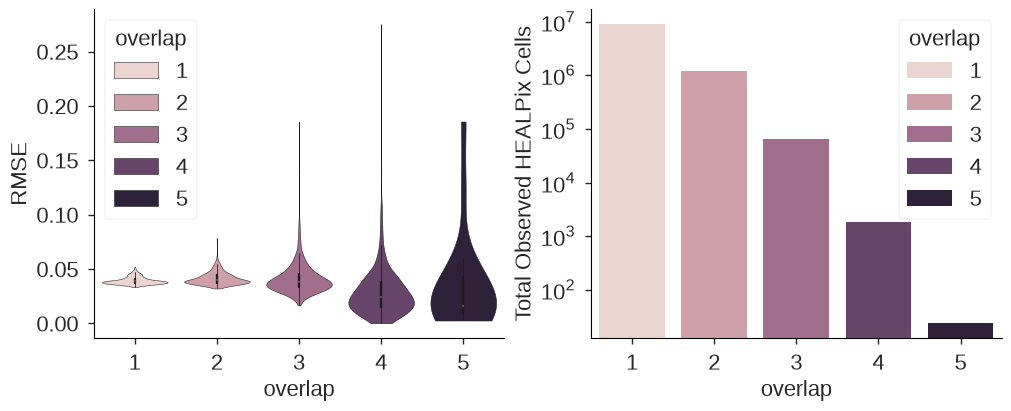

In [11]:
reference = "jason_3"
metrics = ["rmse"]
ncols = len(metrics)+1
fig, axs = plt.subplots(1, ncols, figsize=(5*ncols, 4))

for metric, ax in zip(metrics, axs[:-1]):
    plotme = ds[metric].sel(group=reference).to_dataset().to_dataframe()
    kwargs = {"cut": 0} if metric != "bias" else {}
    sns.violinplot(
        data=plotme,
        x="overlap",
        y=metric,
        hue="overlap",
        ax=ax,
        legend=True if metric != "bias" else False,
        **kwargs,
    )
    ax.set(ylabel=metric.upper())

sns.barplot(
    data=ds["n_obs"].sel(group=reference).sum("t0").to_dataset().to_dataframe(),
    x="overlap",
    y="n_obs",
    hue="overlap",
    ax=axs[-1],
#    legend=False
)
axs[-1].set(yscale="log", ylabel="Total Observed HEALPix Cells")

fig.savefig(f"runs/v2p1/inference-validation/figures/rmse.overlap.{reference}.jpeg", dpi=300, bbox_inches="tight")